<a href="https://colab.research.google.com/github/mayank261193/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP4_AirQuality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breathing in India

# 1. Load and Understand data

In [6]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [10]:
# 2. Load the data and show the first few rows
# Change the file name to match your file (use pd.read_excel for .xlsx)
df = pd.read_csv("mp4_india_city_aqi_2015_2023.csv", low_memory=False)
df.head()

,date,City,No. Stations,Air Quality,Index Value,Prominent Pollutant
0,01-05-2015,Varanasi,NaN,Moderate,157,PM10
1,01-05-2015,Kanpur,NaN,Moderate,175,PM10
2,01-05-2015,Faridabad,NaN,Moderate,173,PM10
3,01-05-2015,Ahmedabad,NaN,Moderate,168,PM2.5
4,01-05-2015,Hyderabad,NaN,Moderate,189,PM2.5


In [8]:
# 3. Shape, column names and data types
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print(df.dtypes)

Shape: (299974, 6)
Columns: ['date', 'City', 'No. Stations', 'Air Quality', 'Index Value', 'Prominent Pollutant']
date                   object
City                   object
No. Stations           object
Air Quality            object
Index Value             int64
Prominent Pollutant    object
dtype: object


In [11]:
# 4. Missing values in every column
print(df.isna().sum())

date                     0
City                     0
No. Stations           140
Air Quality              0
Index Value              0
Prominent Pollutant      1
dtype: int64


In [13]:
# 5. Rows that repeat the same Date and City
# keep=False marks every row in a repeated group, not just the later ones
dup_mask = df.duplicated(subset=["date", "City"], keep=False)
print("Rows sharing a Date + City with another row:", dup_mask.sum())
print("Extra (repeat) rows beyond the first:", df.duplicated(subset=["date", "City"]).sum())
df[dup_mask].sort_values(["City", "date"]).head(10)

Rows sharing a Date + City with another row: 68
Extra (repeat) rows beyond the first: 34


,date,City,No. Stations,Air Quality,Index Value,Prominent Pollutant
179301,01-04-2022,Aurangabad,1,Very Poor,312,PM10
179302,01-04-2022,Aurangabad,1,Moderate,108,PM10
212131,01-11-2022,Aurangabad,1,Moderate,113,PM10
212132,01-11-2022,Aurangabad,1,Moderate,117,PM2.5
183902,02-05-2022,Aurangabad,1,Moderate,102,PM10
183904,02-05-2022,Aurangabad,1,Moderate,128,PM10
212193,02-11-2022,Aurangabad,1,Moderate,107,PM10
212194,02-11-2022,Aurangabad,1,Moderate,144,PM10
179670,03-04-2022,Aurangabad,1,Very Poor,317,PM10
179671,03-04-2022,Aurangabad,1,Moderate,111,PM10


In [17]:
 # 6. Number of cities and the date range
print("Different cities:", df["City"].nunique())
dates = pd.to_datetime(df["date"], errors="coerce")   # works even if Date is text
print("First date:", dates.min())
print("Last date:", dates.max())
print("Dates that could not be read:", dates.isna().sum())

Different cities: 277
First date: 2015-01-05 00:00:00
Last date: 2023-12-12 00:00:00
Dates that could not be read: 182479


In [18]:
 # 7. Count of each value in Air Quality
print(df["Air Quality"].value_counts(dropna=False))
# Inspect exact spellings, including hidden spaces and capital letters
print(sorted(df["Air Quality"].dropna().unique(), key=str))
# "Very poor" is repeated two time with different capitalisation

Air Quality
Satisfactory    105251
Moderate         96139
Good             47440
Poor             34641
Very Poor        13969
Severe            2516
Very poor           18
Name: count, dtype: int64
['Good', 'Moderate', 'Poor', 'Satisfactory', 'Severe', 'Very Poor', 'Very poor']


 what needs cleaning before you can trust this data?                 


  

1.   There are 140 missing station names hence i would drop that column or flag the city and exclude it from comparison.
2.   There is spelling error in Air quality index "Very poor" which lead to error of duplication.



# 2. Clean the Data

In [20]:
df = pd.read_csv("mp4_india_city_aqi_2015_2023.csv", low_memory=False)   # change to your file name
print("Start:", df.shape)

Start: (299974, 6)


In [22]:
# 1. Convert date to datetime with dayfirst=True
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
print("After 1 (datetime):", df.shape)

After 1 (datetime): (299974, 6)


In [23]:
# 2. Fix Air Quality spellings so each category appears once
df["Air Quality"] = df["Air Quality"].str.strip().str.title()
print(df["Air Quality"].value_counts())   # check: each category should appear once
print("After 2 (spellings):", df.shape)

Air Quality
Satisfactory    105251
Moderate         96139
Good             47440
Poor             34641
Very Poor        13987
Severe            2516
Name: count, dtype: int64
After 2 (spellings): (299974, 6)


In [24]:
# 3. Remove repeated city-days, keeping the first one
df = df.drop_duplicates(subset=["City", "date"], keep="first")
print("After 3 (duplicates):", df.shape)

After 3 (duplicates): (299940, 6)


In [28]:
# 4. Drop the No. Stations column safely if it exists
df = df.drop(columns=["No. Stations"], errors="ignore")
print("After 4 (drop column):", df.shape)
# Why it's safe to drop "Stations" Column?
#No. of  Stations only describes how many monitors reported that day
# it do not  tell air quality itself,so it doesn't affect the  analysis.

After 4 (drop column): (299940, 5)


In [29]:
# 5. Create year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
print("After 5 (year, month):", df.shape)

After 5 (year, month): (299940, 7)


In [30]:
# 6. Optional: replace OZONE with O3
df["Prominent Pollutant"] = df["Prominent Pollutant"].replace("OZONE", "O3")
print("After 6 (OZONE -> O3):", df.shape)

After 6 (OZONE -> O3): (299940, 7)


# 3. Describe the AQI with statistics

In [33]:
delhi = df[df["City"] == "Delhi"]

In [34]:
# [1,2,3] Mean, median, std, min, max, Q1, Q3, IQR, skew
def describe(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return {"mean": s.mean(), "median": s.median(), "std": s.std(),
            "min": s.min(), "max": s.max(),
            "Q1": q1, "Q3": q3, "IQR": q3 - q1,
            "skew": s.skew()}

summary = pd.DataFrame({
    "India": describe(df["Index Value"]),
    "Delhi": describe(delhi["Index Value"]),
}).round(2)
print(summary)

         India   Delhi
mean    124.69  217.14
median   99.00  209.00
std      85.09  104.01
min       3.00   41.00
max     500.00  497.00
Q1       62.00  127.00
Q3      162.00  296.00
IQR     100.00  169.00
skew      1.34    0.30


In [35]:
# 4. Count Delhi outliers using the IQR rule
s = delhi["Index Value"]
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_outliers = (s > upper_fence).sum()
print("Upper fence:", upper_fence)
print("Delhi outlier days:", n_outliers)

Upper fence: 549.5
Delhi outlier days: 0


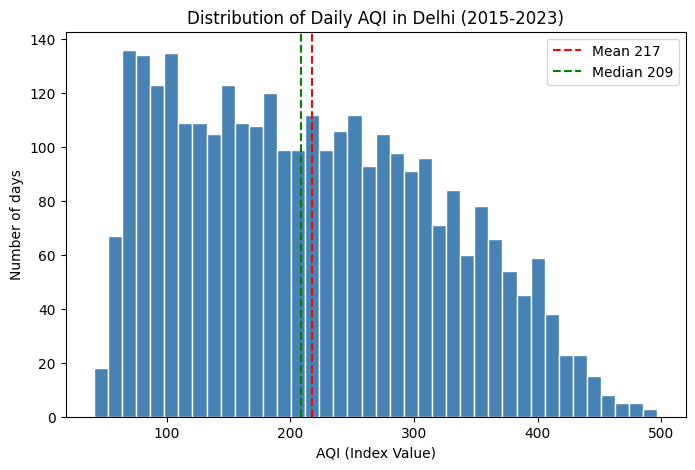

In [36]:
# 5. Histogram of Delhi AQI
plt.figure(figsize=(8, 5))
plt.hist(s, bins=40, color="steelblue", edgecolor="white")
plt.axvline(s.mean(), color="red", ls="--", label=f"Mean {s.mean():.0f}")
plt.axvline(s.median(), color="green", ls="--", label=f"Median {s.median():.0f}")
plt.title("Distribution of Daily AQI in Delhi (2015-2023)")
plt.xlabel("AQI (Index Value)")
plt.ylabel("Number of days")
plt.legend()
plt.show()

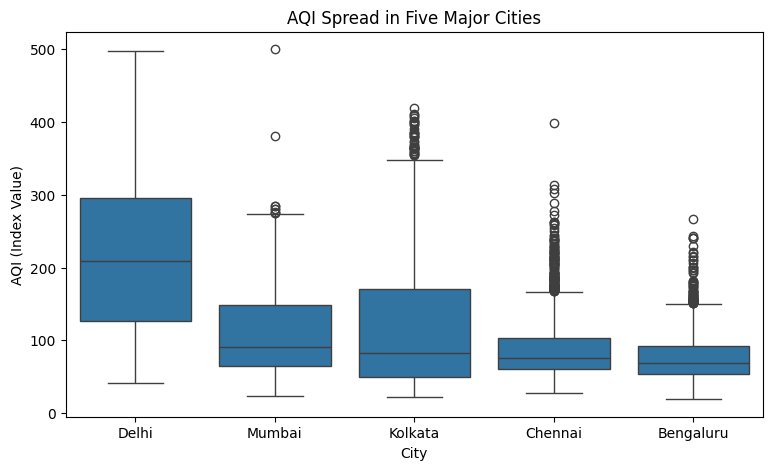

In [37]:
# 6. Box plot comparing five cities
five = ["Delhi", "Mumbai", "Kolkata", "Chennai", "Bengaluru"]
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[df["City"].isin(five)], x="City", y="Index Value", order=five)
plt.title("AQI Spread in Five Major Cities")
plt.xlabel("City")
plt.ylabel("AQI (Index Value)")
plt.show()

Which city has the widest spread?

**Delhi**. It has the highest standard deviation (104) and the widest IQR (169), and Its box sits much higher,hence Delhi is both the most polluted and the most variable of the five.

Is the mean or the median better for a typical Delhi day?

 **The median (209) is the safer choice**, though here the two are close (217 vs 209).The median is better measure for delhi because it is not pulled by extreme days and would stay stable if a few critical days were added.

# 4. Which cities have the worst air?

In [38]:
# 1. Count days per city, keep cities with 2,000+ days
counts = df["City"].value_counts()
big = counts[counts >= 2000].index
df_big = df[df["City"].isin(big)]
print("Cities kept:", len(big), "| shape:", df_big.shape)

Cities kept: 54 | shape: (132735, 7)


In [39]:
# 2. Average AQI per city: 10 worst and 5 best
avg_aqi = (df_big.groupby("City")["Index Value"]
                 .mean()
                 .sort_values(ascending=False))
print("10 worst:\n", avg_aqi.head(10).round(1))
print("5 best:\n", avg_aqi.tail(5).round(1))

10 worst:
 City
Ghaziabad        221.6
Delhi            217.1
Bhiwadi          215.9
Greater Noida    211.0
Noida            206.0
Faridabad        205.6
Gurugram         198.6
Muzaffarpur      193.5
Patna            190.4
Lucknow          181.2
Name: Index Value, dtype: float64
5 best:
 City
Rajamahendravaram     84.4
Amaravati             77.5
Bengaluru             75.4
Tirupati              70.8
Thiruvananthapuram    59.2
Name: Index Value, dtype: float64
